In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


### 1. قراءة البيانات (Data reading)


In [ ]:
df = pd.read_csv('MELBOURNE_HOUSE_PRICES_LESS.csv')
display(df.head())

,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Postcode,Regionname,Propertycount,Distance,CouncilArea
0,Abbotsford,49 Lithgow St,3,h,1490000.0,S,Jellis,1/04/2017,3067,Northern Metropolitan,4019,3.0,Yarra City Council
1,Abbotsford,59A Turner St,3,h,1220000.0,S,Marshall,1/04/2017,3067,Northern Metropolitan,4019,3.0,Yarra City Council
2,Abbotsford,119B Yarra St,3,h,1420000.0,S,Nelson,1/04/2017,3067,Northern Metropolitan,4019,3.0,Yarra City Council
3,Aberfeldie,68 Vida St,3,h,1515000.0,S,Barry,1/04/2017,3040,Western Metropolitan,1543,7.5,Moonee Valley City Council
4,Airport West,92 Clydesdale Rd,2,h,670000.0,S,Nelson,1/04/2017,3042,Western Metropolitan,3464,10.4,Moonee Valley City Council


### 2. تنظيف البيانات (Data Cleaning)
 دالة مخصصة تقوم بالخطوات التالية:
1. إزالة الصفوف المكررة.
2. إسقاط الصفوف التي تفتقر إلى قيمة `Price`.
3. تحويل عمود `Date` إلى التنسيق الزمني القياسي `datetime` لتسهيل تحليل السلاسل الزمنية.

In [ ]:
def clean_housing_data(dataframe):
    # إنشاء نسخة من البيانات لتجنب تعديل الأصل مباشرة
    df_clean = dataframe.copy()
    
    # 1. إزالة الصفوف المكررة
    df_clean = df_clean.drop_duplicates()
    
    # 2. إزالة الصفوف التي لا تحتوي على سعر
    df_clean = df_clean.dropna(subset=['Price'])
    
    # 3. تحويل عمود التاريخ إلى تنسيق زمني (مع تحديد أن اليوم يأتي أولاً)
    df_clean['Date'] = pd.to_datetime(df_clean['Date'], dayfirst=True)
    
    # إعادة ترتيب الكشاف (Index) بعد الحذف
    df_clean = df_clean.reset_index(drop=True)
    
    return df_clean

# تطبيق الدالة على البيانات
df_cleaned = clean_housing_data(df)

# التحقق من نجاح عملية التنظيف
print("البيانات بعد التنظيف:")
print(f"عدد الصفوف: {df_cleaned.shape[0]}")
print(f"عدد القيم المفقودة في السعر: {df_cleaned['Price'].isnull().sum()}")
display(df_cleaned.head())

البيانات بعد التنظيف:
عدد الصفوف: 48432
عدد القيم المفقودة في السعر: 0


,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Postcode,Regionname,Propertycount,Distance,CouncilArea
0,Abbotsford,49 Lithgow St,3,h,1490000.0,S,Jellis,2017-04-01,3067,Northern Metropolitan,4019,3.0,Yarra City Council
1,Abbotsford,59A Turner St,3,h,1220000.0,S,Marshall,2017-04-01,3067,Northern Metropolitan,4019,3.0,Yarra City Council
2,Abbotsford,119B Yarra St,3,h,1420000.0,S,Nelson,2017-04-01,3067,Northern Metropolitan,4019,3.0,Yarra City Council
3,Aberfeldie,68 Vida St,3,h,1515000.0,S,Barry,2017-04-01,3040,Western Metropolitan,1543,7.5,Moonee Valley City Council
4,Airport West,92 Clydesdale Rd,2,h,670000.0,S,Nelson,2017-04-01,3042,Western Metropolitan,3464,10.4,Moonee Valley City Council


### 3. مرحلة التحليل الإحصائي (Data Analysis)
سنبدأ بفحص توزيع المتغيرات بشكل فردي . سنتفحص المتغير الهدف وهو **سعر العقار **، والمتغير الفئوي **نوع العقار **.

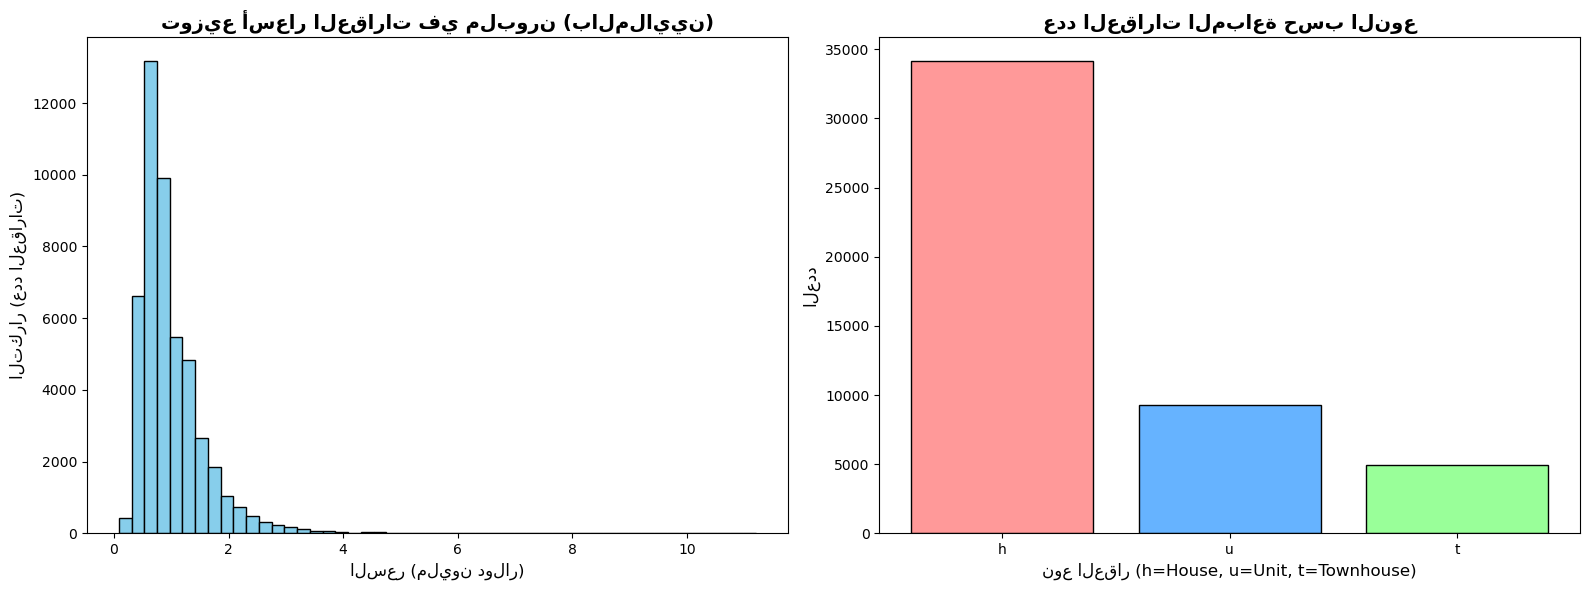


الملخص الإحصائي لأسعار العقارات (Price):


count        48,432
mean        997,898
std         593,505
min          85,000
25%         620,000
50%         830,000
75%       1,220,000
max      11,200,000
Name: Price, dtype: object

In [ ]:
# إعداد حجم الرسمة لتضمين مخططين بجانب بعضهما
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. المخطط الأول: المدرج التكراري (Histogram) باستخدام matplotlib
# نستخدم مقياس الملايين لتسهيل قراءة الأرقام على المحور
axes[0].hist(df_cleaned['Price'] / 1000000, bins=50, color='skyblue', edgecolor='black')
axes[0].set_title('توزيع أسعار العقارات في ملبورن (بالملايين)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('السعر (مليون دولار)', fontsize=12)
axes[0].set_ylabel('التكرار (عدد العقارات)', fontsize=12)

# 2. المخطط الثاني: مخطط شريطي (Bar Chart) باستخدام matplotlib
# نحتاج أولاً لحساب عدد كل فئة قبل رسمها
type_counts = df_cleaned['Type'].value_counts()
colors = ['#ff9999', '#66b3ff', '#99ff99'] # ألوان مخصصة للأعمدة

axes[1].bar(type_counts.index, type_counts.values, color=colors, edgecolor='black')
axes[1].set_title('عدد العقارات المباعة حسب النوع', fontsize=14, fontweight='bold')
axes[1].set_xlabel('نوع العقار (h=House, u=Unit, t=Townhouse)', fontsize=12)
axes[1].set_ylabel('العدد', fontsize=12)

# تحسين المسافات بين المخططات وعرضها
plt.tight_layout()
plt.show()

# طباعة الملخص الإحصائي للسعر لتلبية معيار (التحليل الإحصائي)
print("\nالملخص الإحصائي لأسعار العقارات (Price):")
display(df_cleaned['Price'].describe().apply(lambda x: f"{x:,.0f}"))

مشكلة اللغة العربية تطلع معكوسة ما عرفت احلها، نحتاج نصححها بوقت ثاني

### 4.  التحليل حسب المتغيرات السعر وعدد الغرف والمسافة (Analysis)

1. العلاقة بين الموقع الجغرافي (Regionname) وتوزيع الأسعار (Boxplot).
2. تأثير المسافة عن مركز المدينة (Distance) وعدد الغرف (Rooms) على السعر (Scatter Plot).
3. الاتجاه الزمني لمتوسط أسعار العقارات بمرور الوقت (Line Plot).

C:\Users\07724\AppData\Local\Temp\ipykernel_51304\2143855331.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0].boxplot(price_data, labels=regions, vert=False, patch_artist=True)


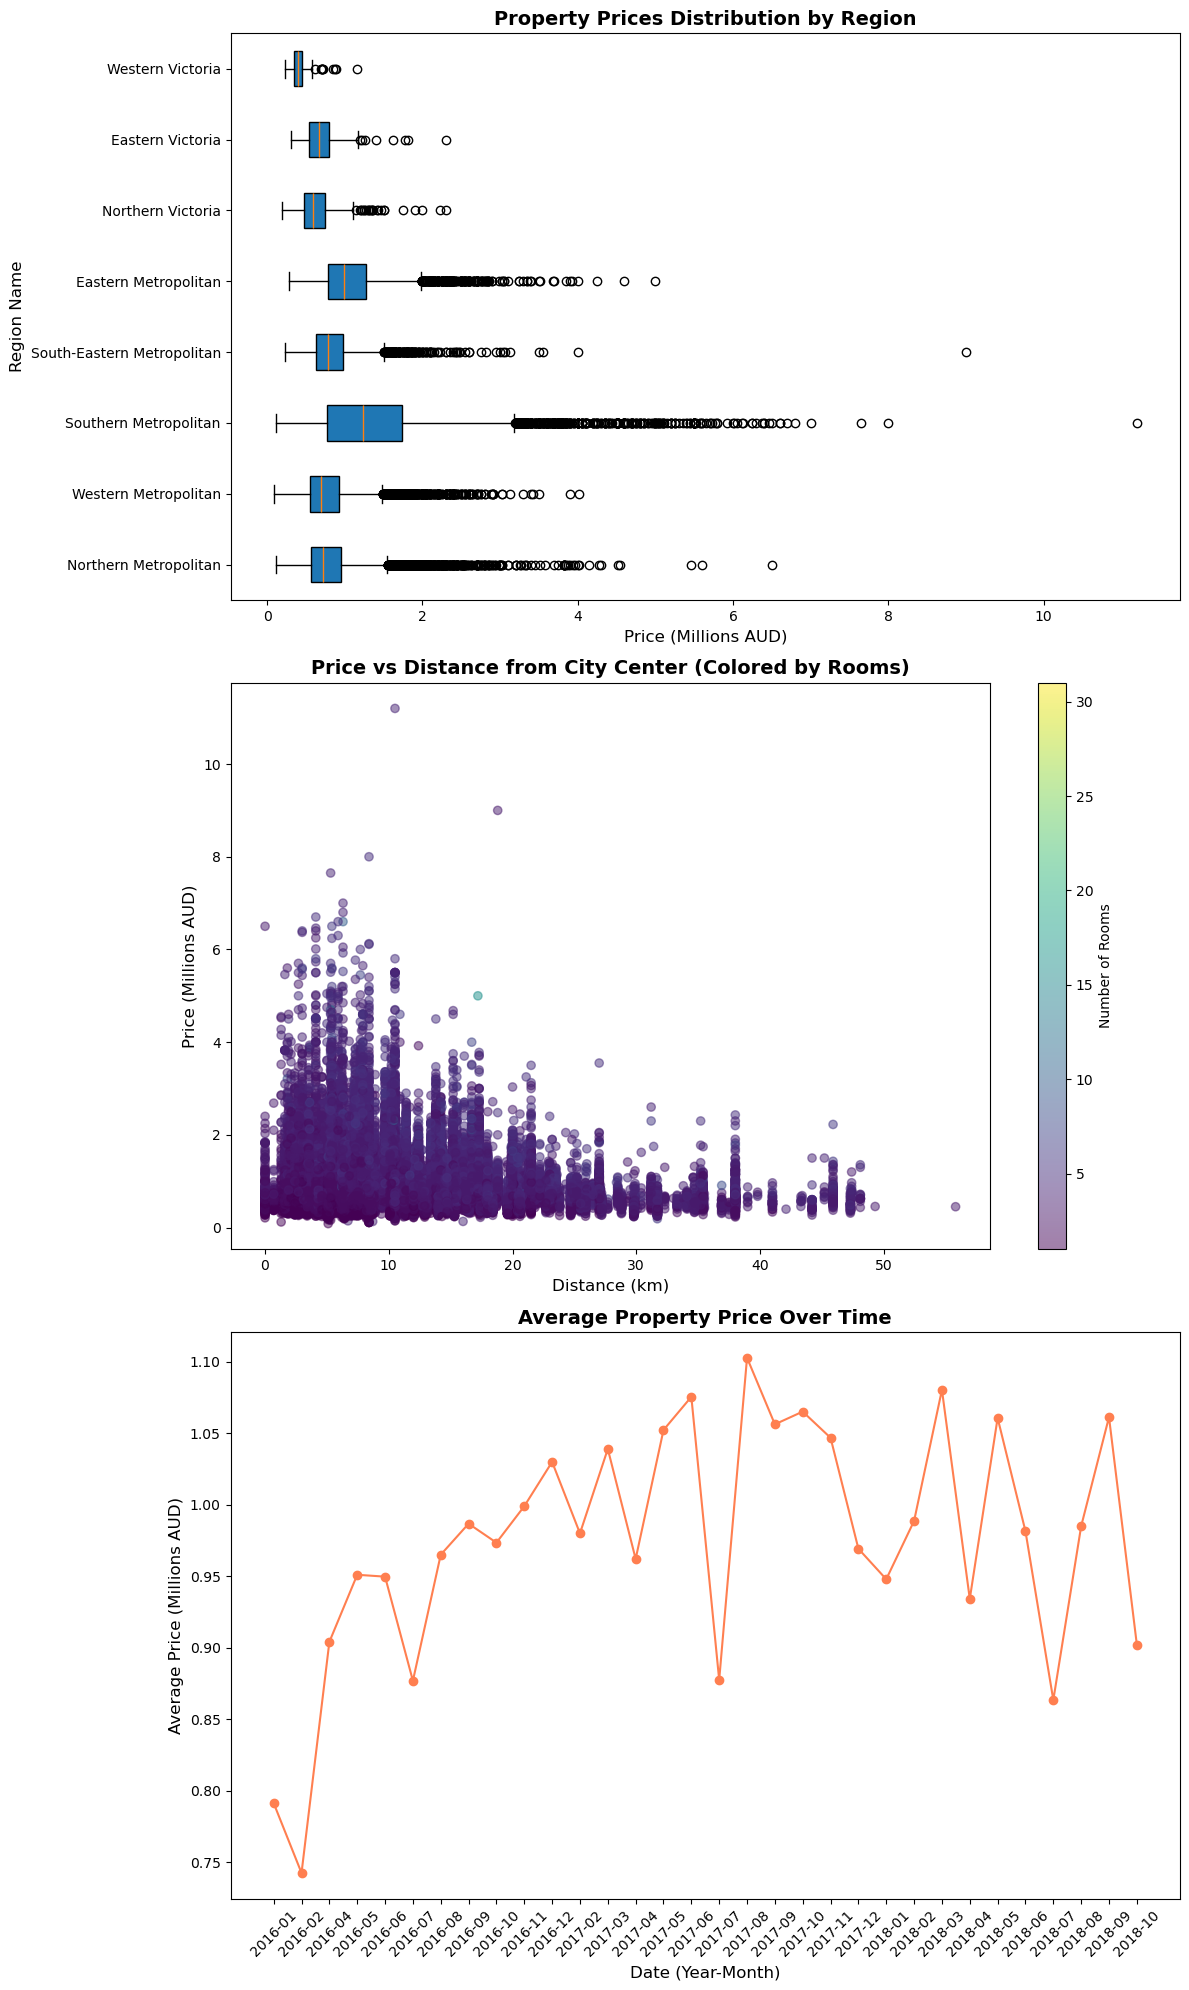


Correlation between Distance and Price:
Correlation Coefficient: -0.25
Conclusion: There is a negative correlation. As distance from the city center increases, the price generally decreases.


In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(12, 20))

# 1. المخطط الصندوقي (Boxplot): مقارنة الأسعار حسب المنطقة الجغرافية
regions = df_cleaned['Regionname'].dropna().unique()
price_data = [df_cleaned[df_cleaned['Regionname'] == r]['Price'] / 1000000 for r in regions]

axes[0].boxplot(price_data, labels=regions, vert=False, patch_artist=True)
axes[0].set_title('Property Prices Distribution by Region', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Price (Millions AUD)', fontsize=12)
axes[0].set_ylabel('Region Name', fontsize=12)

# 2. مخطط التشتت (Scatter Plot): المسافة مقابل السعر (مع تلوين النقاط بعدد الغرف)
# هنا ندمج 3 متغيرات في رسمة واحدة!
scatter = axes[1].scatter(df_cleaned['Distance'], 
                          df_cleaned['Price'] / 1000000, 
                          c=df_cleaned['Rooms'], cmap='viridis', alpha=0.5)
axes[1].set_title('Price vs Distance from City Center (Colored by Rooms)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Distance (km)', fontsize=12)
axes[1].set_ylabel('Price (Millions AUD)', fontsize=12)
fig.colorbar(scatter, ax=axes[1], label='Number of Rooms')

# 3. المخطط الخطي (Line Plot): متوسط السعر بمرور الزمن (Date)
# تجميع البيانات حسب الشهر وحساب متوسط السعر
monthly_price = df_cleaned.groupby(df_cleaned['Date'].dt.to_period('M'))['Price'].mean() / 1000000

axes[2].plot(monthly_price.index.astype(str), monthly_price.values, marker='o', linestyle='-', color='coral')
axes[2].set_title('Average Property Price Over Time', fontsize=14, fontweight='bold')
axes[2].set_xlabel('Date (Year-Month)', fontsize=12)
axes[2].set_ylabel('Average Price (Millions AUD)', fontsize=12)
axes[2].tick_params(axis='x', rotation=45) # تدوير التواريخ لتسهيل القراءة

# تحسين المسافات بين المخططات
plt.tight_layout()
plt.show()

# طباعة الملخص الإحصائي (معامل الارتباط) لتلبية معيار (الإحصائيات)
print("\nCorrelation between Distance and Price:")
correlation = df_cleaned['Distance'].corr(df_cleaned['Price'])
print(f"Correlation Coefficient: {correlation:.2f}")
if correlation < 0:
    print("Conclusion: There is a negative correlation. As distance from the city center increases, the price generally decreases.")